In [1]:
from sklearn.ensemble import IsolationForest
print("ok")

ok


In [3]:
import json, os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
print("basic imports ok")

basic imports ok


In [4]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score
print("sklearn ok")

sklearn ok


In [5]:
DATA_DIR = "../data/realAWSCloudwatch"
files = sorted(glob.glob(f"{DATA_DIR}/*.csv"))

with open("../data/labels/combined_windows.json") as f:
    windows = json.load(f)

name = os.path.basename(files[2])
df = pd.read_csv(f"{DATA_DIR}/{name}", parse_dates=["timestamp"])

wins = [(pd.to_datetime(s), pd.to_datetime(e))
        for s, e in windows.get(f"realAWSCloudwatch/{name}", [])]

label = np.zeros(len(df), dtype=int)
for s, e in wins:
    label |= ((df["timestamp"] >= s) & (df["timestamp"] <= e)).values.astype(int)
df["label"] = label

print(name, df.shape, "| windows:", len(wins), "| anomalous points:", df["label"].sum())

ec2_cpu_utilization_5f5533.csv (4032, 3) | windows: 2 | anomalous points: 402


In [6]:
W = 12                                   # previous 12 readings (about 1 hour)
v = df["value"]
prev = v.shift(1)                        # keeps the current reading out of its own baseline

df["roll_mean"] = prev.rolling(W).mean()
df["roll_std"]  = prev.rolling(W).std()
df["zscore"]    = (v - df["roll_mean"]) / df["roll_std"]
df["diff1"]     = v.diff()

df = df.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)
FEATURES = ["value", "roll_mean", "roll_std", "zscore", "diff1"]
df[FEATURES].describe()

,value,roll_mean,roll_std,zscore,diff1
count,4020.000000,4020.000000,4020.000000,4020.000000,4020.000000
mean,43.099959,43.113067,2.754663,-0.009187,-0.002986
std,4.300555,3.181725,1.245661,1.075575,5.072660
min,34.766000,37.719833,0.454928,-4.027276,-30.276000
25%,39.290500,38.535542,1.409030,-0.673558,-3.244000
50%,42.910000,43.606250,3.042799,-0.147738,-0.399000
75%,45.986000,46.092333,3.659014,0.622163,2.115000
max,68.092000,49.468525,9.356527,5.703226,22.200000


In [7]:
df["pred_z"] = (df["zscore"].abs() > 3).astype(int)
print("Baseline flags:", df["pred_z"].sum())

Baseline flags: 25


In [8]:
split = int(len(df) * 0.3)

iso = IsolationForest(n_estimators=200, random_state=42)
iso.fit(df.loc[:split, FEATURES])

df["iso_score"] = -iso.score_samples(df[FEATURES])     # higher = more unusual
thr = df["iso_score"].iloc[:split].quantile(0.995)     # threshold from the training period
df["pred_iso"] = (df["iso_score"] > thr).astype(int)
print("Isolation Forest flags:", df["pred_iso"].sum())

Isolation Forest flags: 1374


In [9]:
def evaluate(col):
    pred = df[col].values
    p = precision_score(df["label"], pred, zero_division=0)
    r = recall_score(df["label"], pred, zero_division=0)
    f = f1_score(df["label"], pred, zero_division=0)
    caught = 0
    for s, e in wins:
        m = ((df["timestamp"] >= s) & (df["timestamp"] <= e)).values
        caught += int(pred[m].sum() > 0)
    print(f"{col}: precision={p:.2f}  recall={r:.2f}  F1={f:.2f}  windows caught={caught}/{len(wins)}")

evaluate("pred_z")
evaluate("pred_iso")

pred_z: precision=0.16  recall=0.01  F1=0.02  windows caught=2/2
pred_iso: precision=0.09  recall=0.30  F1=0.13  windows caught=2/2


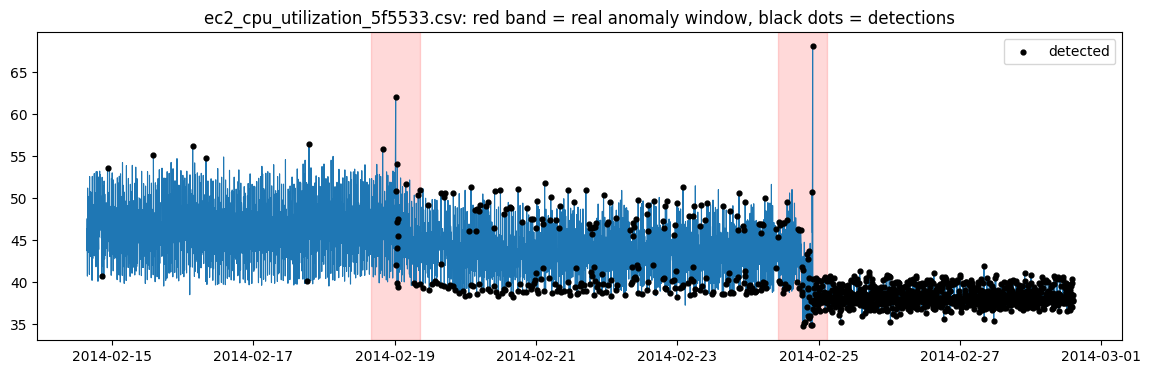

In [10]:
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df["timestamp"], df["value"], linewidth=0.8)
for s, e in wins:
    ax.axvspan(s, e, color="red", alpha=0.15)
flag = df[df["pred_iso"] == 1]
ax.scatter(flag["timestamp"], flag["value"], color="black", s=12, zorder=3, label="detected")
ax.legend()
ax.set_title(f"{name}: red band = real anomaly window, black dots = detections")
plt.show()